# Part 3 | Single neurons: spike sorting, curation & firing statistics

In Part 2 you detected spikes per **channel** — *multi-unit activity (MUA)*.
One electrode usually hears several neurons. **Spike sorting** groups spikes by
waveform shape to assign each to a putative single neuron — *single-unit
activity (SUA)*. We sorted your recordings with **Kilosort**; the result is
referenced by `sorted_files`.

Not every sorted unit is a clean neuron, so we first **curate** the units, then
ask *how* the neurons fire. An analysis of their spike *shapes* follows in Part 4.

## Goal

Go from electrodes to single neurons: decide which sorted units to trust, and describe how they fire.

By the end of this part you can:
- curate sorted units with Kilosort's label and refractory violations
- quantify a neuron's firing pattern with the Fano factor and the CV of the ISI
- read the distributions of these features over all units

> **How the exercises work.** You will meet three kinds of boxes:
> - **✎ Your turn** — one line of code to complete: look for `# TODO` and the
>   obviously-wrong placeholder (e.g. `0.0`). The explanation or worked example
>   just above it shows what you need, and a **check** prints `[OK]` when you
>   got it, or a hint if not.
> - **💬 Discuss:** — a question to discuss with your partner. No code, no check.
> - **🔧 Try it:** — an optional experiment: change a value, re-run, and see what
>   happens. Set it back afterwards.
>
> The full answers live in `mea_helpers.py` if you ever want to peek.

In [1]:
# ========================= YOUR SETTINGS ==============================
GROUP_ID  = 1            # your group number (data exists for groups 1 and 2)
DRUG      = "A"          # config / drug label:  group 1 -> A,B,C,D   group 2 -> A,B
CONDITION = "Baseline"   # "Baseline" or "Drug"

# Path to YOUR group's manifest: the recordings.toml in your group folder on
# the bs-dfs share (the exact path is handed out with the practical), e.g.
#   r"Z:\BEL\Practicals_2026\Group_01\recordings.toml"
MANIFEST  = r"PASTE-THE-PATH-TO-YOUR-recordings.toml"

# The manifest stores full paths to the data, so DATA_ROOT is not used here.
# (Leave as ".": it only matters if your manifest uses relative paths.)
DATA_ROOT = "."
# ======================================================================

import sys; sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import mea_helpers as mea

manifest = mea.load_manifest(MANIFEST)
row = mea.find_recording(manifest, GROUP_ID, DRUG, CONDITION)
print("Selected recording:"); print(row)

Selected recording:
UID                        G05_A_Baseline
GroupID                                 5
Chip                               maxtwo
Drug                                    A
Conditions                       Baseline
Well                                    0
raw_files       raw/G05_A_Baseline.raw.h5
sorted_files        sorted/G05_A_Baseline
Name: 0, dtype: object


## 1. Load the recording and the sorted units

In [2]:
recording = mea.open_recording(row, data_root=DATA_ROOT)
fs = recording.get_sampling_frequency()
duration = recording.get_num_frames() / fs

sorting = mea.load_sorting(row, data_root=DATA_ROOT)
sua = mea.sorting_to_spikes(sorting)          # tidy table: time (s), unit
print(f"{sua['unit'].nunique()} units, {len(sua)} spikes in {duration:.0f} s")
sua.head()

361 units, 176657 spikes in 120 s


,time,unit
0,0.00030,172
1,0.00090,20
2,0.00135,76
3,0.00180,350
4,0.00195,181


## 2. Which units can we trust? (curation)

A spike sorter returns *clusters*, and not all of them are single neurons. Both
checks we use rest on the same biological fact, the **refractory period (RP)
rule**: after an action potential, a neuron cannot fire again for about
**1–2 ms**. Spikes of *one* neuron are therefore never closer than that; if a
cluster has many such short intervals, it must contain spikes of more than one
neuron (or noise).

1. **Kilosort's label (`good` / `mua`).** Kilosort4 applies the RP rule to the
   unit's **autocorrelogram** (the histogram of time differences between all
   its spikes): it compares the spike rate within ±1–10 ms with the rate at
   longer lags (10–500 ms). A unit is `good` if this short-lag rate is **below
   20 %** of the baseline *and* the dip is statistically significant; otherwise
   it is `mua` (multi-unit activity). The label says nothing about the
   waveform — only about refractoriness.
2. **Refractory violations (our extra check).** We count the **consecutive**
   inter-spike intervals (ISIs) shorter than **1.5 ms** and keep units with
   **fewer than 1 %** of their ISIs below it. 1.5 ms is the default refractory
   period in spikeinterface; 1 % is a common rule of thumb, but labs use
   1–3 ms and 0.5–1 %. It is stricter in the very shortest lags, where
   Kilosort's ±1–10 ms window averages over a longer stretch.

`mea.unit_features` computes, per unit, the Kilosort label, the % of ISI
violations and the firing statistics we use below.

In [3]:
feats = mea.unit_features(sua, duration, sorting=sorting, recording=recording)
print(feats["ks_label"].value_counts())
feats.groupby("ks_label")["isi_violation_pct"].describe().round(2)

ks_label
good    236
mua     125
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
ks_label,,,,,,,,
good,236.0,0.23,0.64,0.0,0.00,0.00,0.32,8.38
mua,125.0,1.93,2.61,0.0,0.31,1.06,2.44,18.08


The same numbers as histograms, one per Kilosort label: how many units have
which share of refractory violations. The dashed line is the 1 % limit.
**Solid bars** are the units we keep (Kilosort `good` *and* below 1 %);
**light, hatched bars** are excluded: `good` units above the limit (grey band)
and every `mua` unit, whatever its violations.

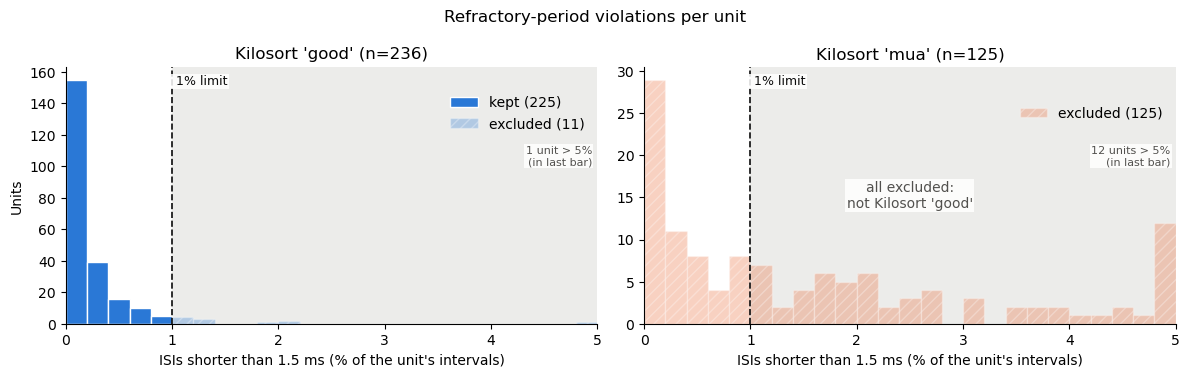

In [4]:
mea.plot_isi_violations(feats)
plt.suptitle("Refractory-period violations per unit"); plt.tight_layout(); plt.show()

> **💬 Discuss:** most `good` units sit close to 0 %. Where are the `mua` units? Would the ISI
> check alone have been enough to separate them, or does it add something to
> Kilosort's label?

### An alternative: Hill et al.'s contamination estimate

Our 1 % rule asks *what share of the ISIs* is too short. Hill et al. (2011)
ask a different question: **what fraction of the unit's spikes is
contamination?** If contaminating spikes arrive at random, the number of
violations they cause grows with how many spikes there are and how long the
recording is. Turned around, this gives an estimate of the contamination:

$$C = \frac{n_v \, T}{2 \, N^2 \, t_r}$$

with $n_v$ violations (ISIs shorter than $t_r$ = 1.5 ms), $N$ spikes and $T$ the
recording duration in seconds. $C \approx 0.5$ means contaminating spikes occur
at about half the rate of the true ones. This is spikeinterface's
`isi_violations_ratio`, and the Allen Institute keeps units with **C < 0.5**.
`mea.unit_features` already computed it, as `isi_violation_ratio`.

The same plot with $C$ instead of the %, again with Kilosort's label:

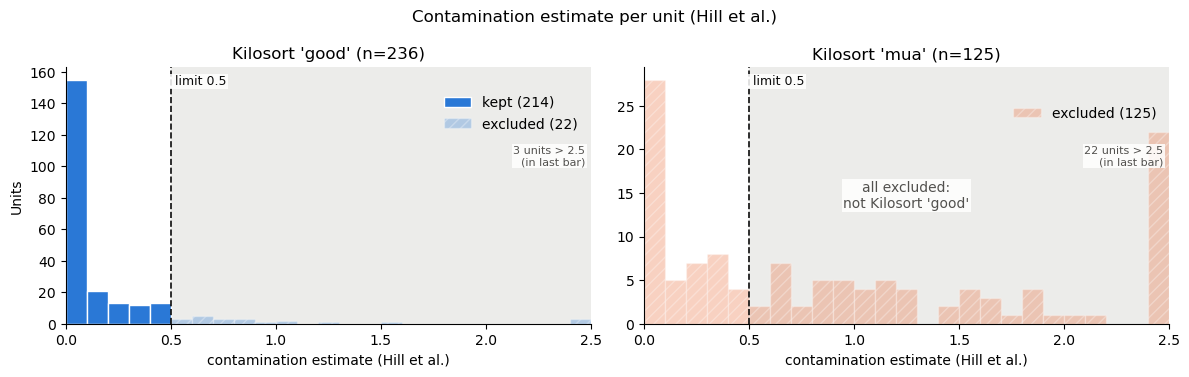

In [5]:
mea.plot_isi_violations(feats, metric="isi_violation_ratio",
                        max_isi_violation_pct=0.5, xmax=2.5)
plt.suptitle("Contamination estimate per unit (Hill et al.)"); plt.tight_layout(); plt.show()

Do the two rules keep the same units? Both require Kilosort's `good`; they
differ only in the refractory check.

In [6]:
ours = mea.curate_units(feats)                         # good + < 1 % of ISIs
hill = mea.curate_units_hill(feats, max_ratio=0.5)      # good + C < 0.5
both = ours.index.intersection(hill.index)

print(f"1 % rule : {len(ours)} units")
print(f"Hill C<0.5: {len(hill)} units")
print(f"kept by both: {len(both)};  only by the 1 % rule: "
      f"{len(ours.index.difference(hill.index))};  only by Hill: "
      f"{len(hill.index.difference(ours.index))}")

1 % rule : 225 units
Hill C<0.5: 214 units
kept by both: 212;  only by the 1 % rule: 13;  only by Hill: 2


> **💬 Discuss:** the two rules keep almost the same units. Why? Both count the
> *same* short ISIs, but Hill's estimate also takes the firing rate into
> account. Look at the units only one rule keeps, e.g.
> `feats.loc[ours.index.difference(hill.index)]`: how fast do they fire? For a
> slowly firing neuron, even a few short ISIs are unlikely by chance — so which
> rule is stricter for slow units, and which for fast ones?

> **Further reading — how others curate**
> - Kilosort4: [Pachitariu et al. 2024, *Nat Methods*](https://doi.org/10.1038/s41592-024-02232-7);
>   the `good`/`mua` rule is in [`CCG.py`](https://github.com/MouseLand/Kilosort/blob/main/kilosort/CCG.py)
>   (`acg_threshold=0.2`) and [Kilosort docs: custom good/mua labels](https://kilosort.readthedocs.io/en/latest/tutorials/good_unit_criteria.html).
> - Estimating contamination from RP violations: [Hill, Mehta & Kleinfeld 2011, *J Neurosci* 31:8699](https://www.jneurosci.org/content/31/24/8699).
> - spikeinterface quality metrics ([ISI violations](https://spikeinterface.readthedocs.io/en/0.101.0/modules/qualitymetrics/isi_violations.html)):
>   `isi_violations_ratio` (Hill et al.) and `rp_contamination` (Llobet et al. 2022).
> - Allen Institute Neuropixels data: [quality metrics](https://allensdk.readthedocs.io/en/stable/_static/examples/nb/ecephys_quality_metrics.html),
>   default filter `isi_violations < 0.5`, plus amplitude cutoff and presence ratio.

### ✎ Your turn — keep only the clean units

Keep the units that Kilosort labelled `good` **and** that have **fewer than 1 %**
refractory violations. The ISI condition below has the wrong comparison.

In [7]:
# TODO: keep units with FEWER than 1 % ISI violations: change > into <.
clean = feats[(feats["ks_label"] == "good") & (feats["isi_violation_pct"] > 1.0)]

print(f"kept {len(clean)} of {len(feats)} units")
mea.check(len(clean), len(mea.curate_units(feats)),
          hint='use feats["isi_violation_pct"] < 1.0')

kept 11 of 361 units
[X] not quite yet.
   hint: use feats["isi_violation_pct"] < 1.0
   you got: 11
   expected ~ 225


False

From here on we only use the curated units. Parts 4–6 apply the same curation
with `mea.curate_units(feats)`.

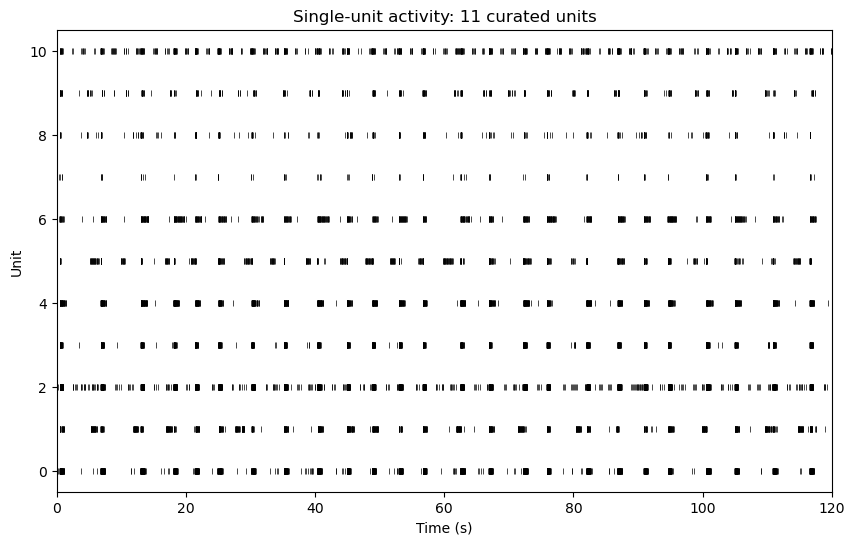

In [8]:
sua_clean = sua[sua["unit"].isin(clean.index)]
mea.plot_raster(sua_clean, duration=duration)
plt.title(f"Single-unit activity: {len(clean)} curated units"); plt.show()

## 3. How does a neuron fire? Fano factor and CV of the ISI

Two numbers describe the *pattern* of a spike train, beyond its rate:

| Measure | Poisson (random) | Regular | Bursty |
|---|---|---|---|
| **Fano** = var/mean of spike counts in 1 s bins | ≈1 | <1 | >1 |
| **CV_ISI** = SD/mean of inter-spike intervals | ≈1 | ≈0 | >1 |

They only make sense for **single neurons**: on a channel (MUA), the spikes of
several neurons interleave, which hides each neuron's own pattern.

We work on the curated unit with the most spikes.

In [9]:
uid = clean["n_spikes"].idxmax()
st = sua_clean.loc[sua_clean["unit"] == uid, "time"].to_numpy()   # spike times (s)
print(f"unit {uid}: {len(st)} spikes, {mea.firing_rate(st, duration):.2f} Hz")

unit 122: 1294 spikes, 10.78 Hz


### ✎ Your turn — Fano factor

In [10]:
edges  = np.arange(0, duration + 1.0, 1.0)     # 1 s bins
counts, _ = np.histogram(st, bins=edges)       # spikes per bin

# TODO: Fano = variance / mean. Replace .max() with the right statistic.
fano = counts.var() / counts.max()

mea.check(fano, mea.fano_factor(st, duration, bin_s=1.0),
          hint="Fano = counts.var() / counts.mean()")

[X] not quite yet.
   hint: Fano = counts.var() / counts.mean()
   you got: 3.803004387271535
   expected ~ 16.713822218248236


False

### ✎ Your turn — CV of the inter-spike intervals

In [11]:
isi = np.diff(np.sort(st))        # intervals between consecutive spikes (s)

# TODO: CV = standard deviation / mean. Fix the denominator.
cv_isi = isi.std() / isi.max()

mea.check(cv_isi, mea.cv_isi(st), hint="CV = isi.std() / isi.mean()")

[X] not quite yet.
   hint: CV = isi.std() / isi.mean()
   you got: 0.1251460546095898
   expected ~ 2.776865749471757


False

## 4. The whole population: distributions of single-cell features

One unit is an anecdote; the figures show **all** curated units at once. For
each feature: a **histogram** of how it is distributed over the units, and a
**map** of *where* the units are on the chip (grey dots: the recorded
electrodes).

### Footprint size

On how many electrodes is Kilosort's template of the unit seen? Histogram on
the left; the map on the right shows each unit's footprint electrodes in its
own colour (colours repeat for distant units).

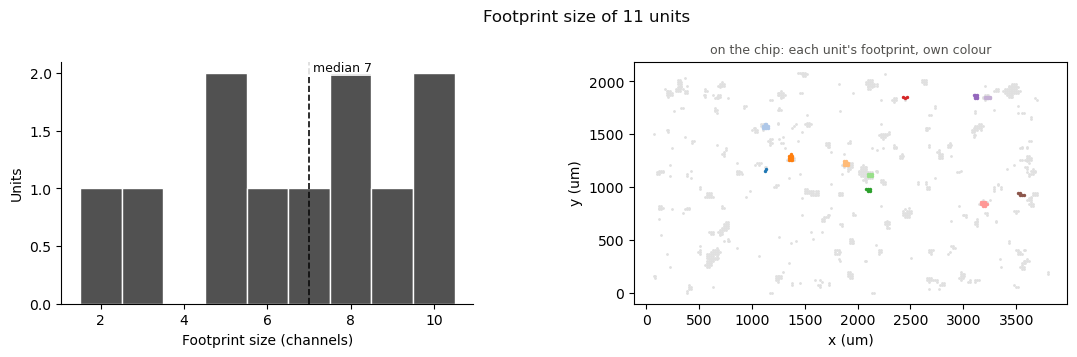

In [12]:
mea.plot_unit_features(clean, recording=recording, features=["footprint_size"])
plt.show()

### Firing statistics

**Firing rate**, **CV of ISI** and **Fano factor**: histograms in the top row;
in the maps below, each unit is coloured by the feature above it.

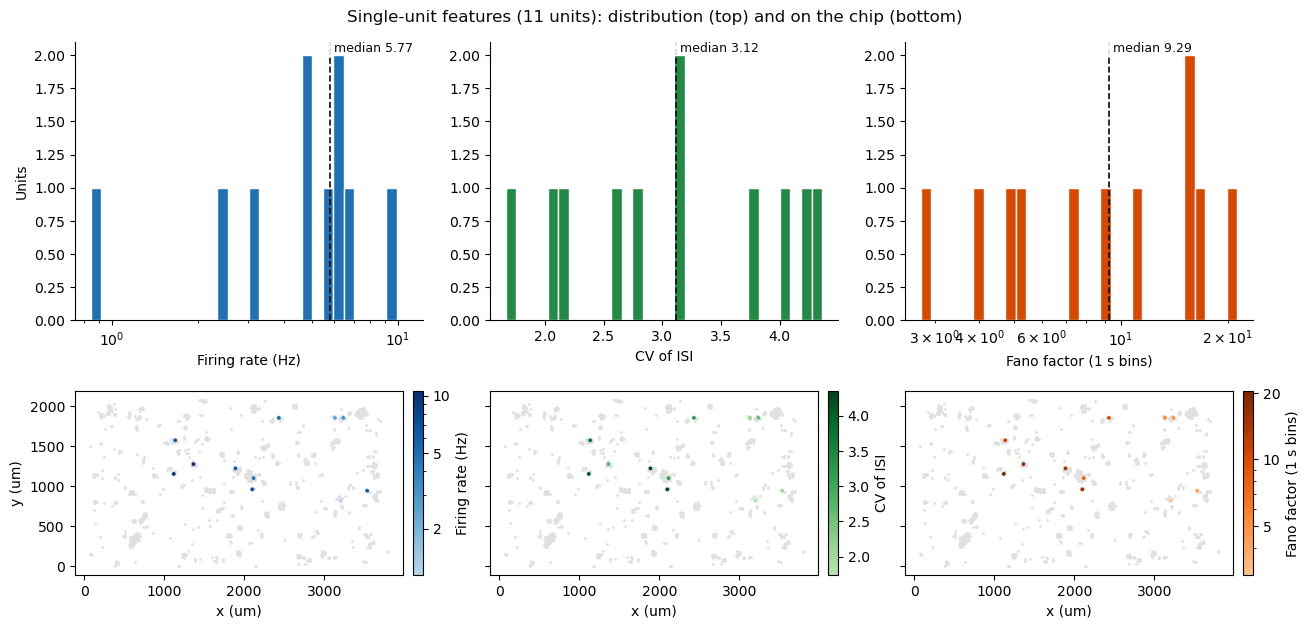

In [13]:
mea.plot_unit_features(clean, recording=recording,
                       features=["firing_rate_hz", "cv_isi", "fano"])
plt.show()

> **🔧 Try it:** choose other features with `features=[...]`, e.g.
> `mea.plot_unit_features(clean, recording, features=["n_spikes", "isi_violation_pct", "isi_violation_ratio"])`.
> `mea.UNIT_FEATURES` lists all of them.

> **💬 Discuss:**
> - Firing rates span orders of magnitude, hence the log axis. Where does the
>   bulk of units sit, and how long is the low-rate tail?
> - Most units have a CV of ISI and a Fano factor well **above 1** (Poisson).
>   What does that say about how these neurons fire?
> - Bottom row: are units with a large footprint, a high rate or a high Fano
>   factor spread over the whole chip, or clustered in some regions?